# Network Intrusion Detection

In [1]:
import sys
sys.path.append("..")  # so we can import the src package from the notebooks/ folder

from src.cic_data_loader import *
from src.preprocessing import *
from src.model import *
from src.evaluate import *
from src.neural_net import *

## 1. Download and load the data

In [2]:
df = cic_load_data(data_dir="../data/data_cic")

train, test = split_by_day(df)

print("Training rows:", len(train))
print("Test rows:", len(test))
train.head(20)

Training rows: 1947674
Test rows: 615433


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day,is_attack
703245,49188,4,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703246,49188,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703249,49486,3,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703250,49486,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703253,88,609,7,4,484,414,233,0,69.142857,111.967895,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703254,88,879,9,4,656,3064,313,0,72.888889,136.153814,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703255,88,1160,9,6,3134,3048,1552,0,348.222222,682.482560,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703256,88,524,7,4,2812,2820,1397,0,401.714286,679.914876,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703257,1034,6,1,1,6,6,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703258,88,1119,9,6,3160,3060,1565,0,351.111111,688.214982,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0


## 2. Prepare features

This encodes the text columns (`protocol_type`, `service`, `flag`) into numbers and scales everything, since logistic regression needs numeric, comparably-sized inputs.

In [3]:
X_train, X_test, y_train, y_test, scaler = prepare_cic_features(train, test, drop_cols=("Label", "Day", "is_attack"))

print("Feature matrix shape:", X_train.shape)

Feature matrix shape: (1947674, 77)


## 3. Train the model

In [4]:
model = train_model(X_train, y_train)
print("Model trained")

Model trained


## 4. Evaluate

We look at accuracy, precision, and recall rather than just accuracy, since missing an attack is usually worse than a false alarm.

In [5]:
y_pred = predict(model, X_test)
print_report(y_test, y_pred)

Accuracy:  0.7739
Precision: 0.9968
Recall:    0.3705

Confusion matrix (rows=actual, cols=predicted):
[[394514    263]
 [138911  81745]]

              precision    recall  f1-score   support

      normal       0.74      1.00      0.85    394777
      attack       1.00      0.37      0.54    220656

    accuracy                           0.77    615433
   macro avg       0.87      0.68      0.70    615433
weighted avg       0.83      0.77      0.74    615433



## 5. Create a neural network to compare

I made two single hidden layer neural network to compare against the linear regression model. These are signifigantly heavier than the linear regresion and might take a couple minutes depending on your hardware.

In [6]:
#32 nodes with 42 random states
mlp_model = train_mlp(X_train, y_train, hidden_layer_size=(32,))
#64 nodes with 64 random states
mlp_model_2 = train_mlp(X_train, y_train, hidden_layer_size=(64,), random_state=64)
#two sets of 32 and 16 nodes with 42 random states
mlp_model_3 = train_mlp(X_train, y_train, hidden_layer_size=(32, 16))

## 6. Compare the new models

           Logistic Regression  Neural Net (32 nodes)  Neural Net (64 nodes)  \
Accuracy              0.773860               0.744630               0.707879   
Precision             0.996793               0.997602               0.987524   
Recall                0.370464               0.288440               0.187613   

           Neural Net (32-16 nodes)  
Accuracy                   0.762840  
Precision                  0.998306  
Recall                     0.339112  


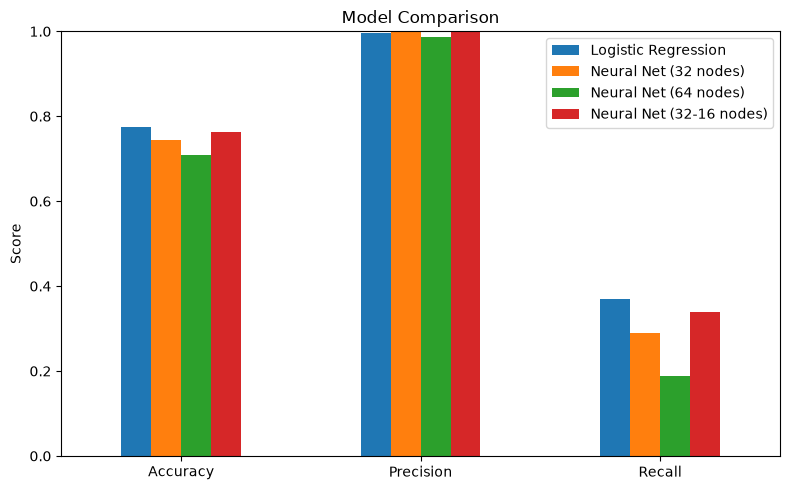

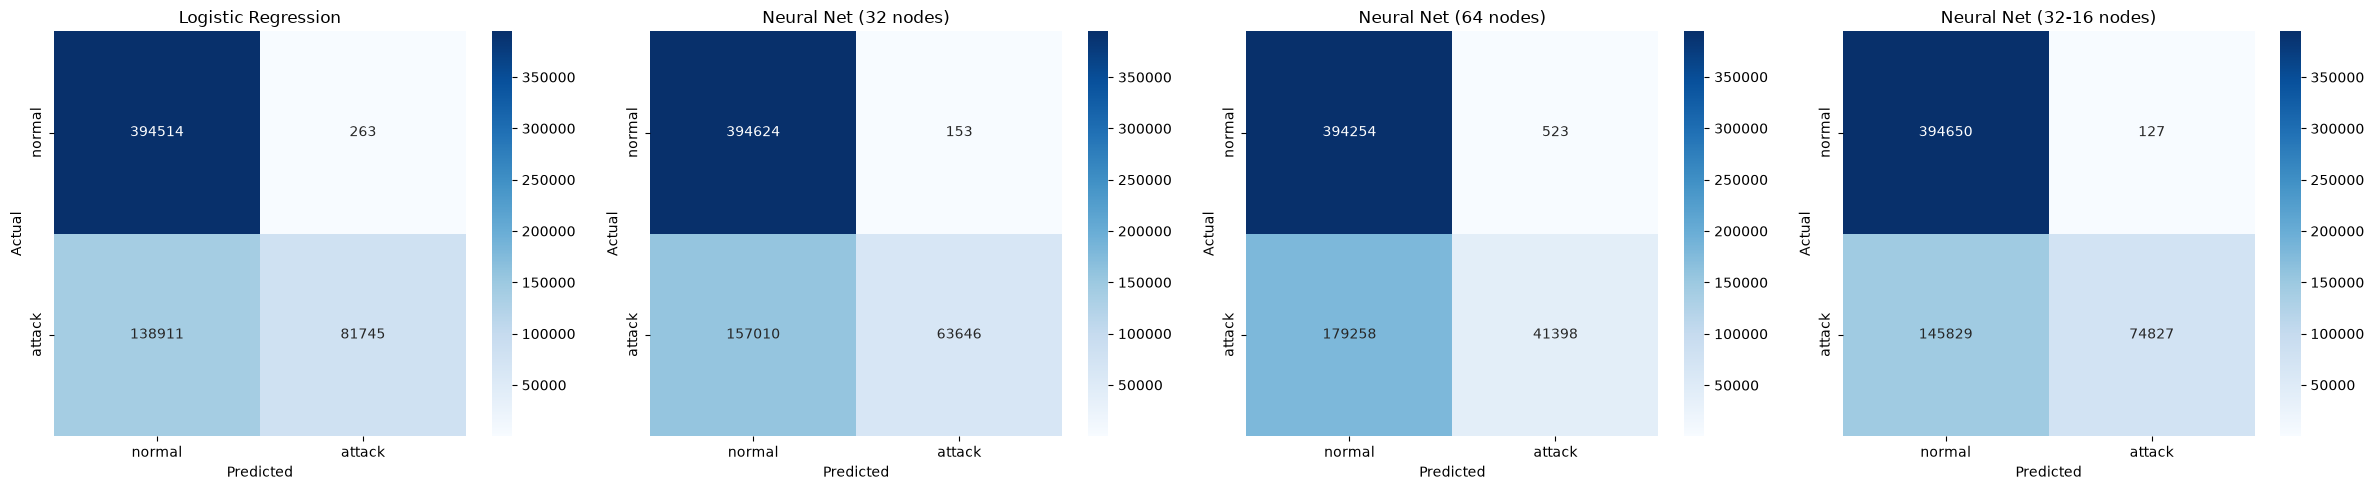

In [7]:
from src.compare import compare_models, plot_comparison

lr_model = model

models = {
    "Logistic Regression": lr_model,
    "Neural Net (32 nodes)": mlp_model,
    "Neural Net (64 nodes)": mlp_model_2,
    "Neural Net (32-16 nodes)": mlp_model_3,
}

results_df, confusion_matrices = compare_models(models, X_test, y_test)
print(results_df)
plot_comparison(results_df, confusion_matrices)